# A00 · 채권–KOSPI 환경설정: 데이터 계약과 수익률 정의

**Track A · Phase A1** — R2H Cross-Asset EDA. 이 노트북은 A01·A012·A02(상관 분석·사건 후보)가 **같은 입력·같은 정의**를 쓰도록
기준을 고정하는 교재 겸 감사 기록이다.

| 항목 | 값 |
|---|---|
| 기준 commit | `d5c2f79` (ETF Universe Domain EDA Report FINAL) · branch `codex/r2h-track-a` |
| 입력 | ETF 20종 FDR raw (READ-ONLY, 공유 절대경로) · canonical `data/interim/panel_*.csv` |
| 계약 | `config/research_a_contract.yaml` |
| 코드 | `src/r2h/research_a/` (`contract` · `data` · `qa` · `a1_pipeline`) — 기존 `src/eda_utils.py`, `src/final_figs.py` 는 수정하지 않음 |
| 산출 | `reports/r2h/research_a/a1/` (QA 표 + `A1_RUN_MANIFEST.json`) · `data/processed/research_a/<run_id>/` (파생 패널) |

**이 노트북이 하지 않는 것**: 상관 계산(A2), 급등 정의·사건 탐지(A3), raw 재수집, 가격 보정, DQ 관측치 삭제.

### 문제 제기
"KOSPI200 과 국고채 ETF 의 상관이 언제 부호를 바꾸는가"를 묻기 전에, 다음이 먼저 정해져야 한다.
1. 두 시계열이 **같은 날짜**에 **같은 정의의 수익률**로 정렬돼 있는가?
2. 그 수익률이 **기존 EDA(42 노트북·243 그림)와 같은 숫자**인가? 아니면 다른 결과의 원인이 데이터 차이인가 방법 차이인가?
3. 의심스러운 관측치(DQ flag 220건)가 **상관이라는 결론에 닿는 경로**에 있는가?
4. KOSPI200 ETF 2종(069500·102110)을 **두 개의 독립 증거**로 셀 위험은 없는가?

## 0. 실행 환경과 run_id

커널 `hongik_26_2` 의 `PYTHONPATH` 는 이 작업 트리를 가리키지 않는다. 그래서 첫 셀에서 계약 파일을 찾아 **작업 트리 루트**를 잡는다.
`run_id` 와 `input_data_version` 은 이후 모든 산출물에 열로 붙는다 — 표 하나만 봐도 "어느 실행, 어느 raw" 인지 알 수 있게.

- `input_data_version` = sha256( 정렬된 `ticker:sha256` 20줄 ) — raw 20 파일 내용의 지문. 파일 하나만 바뀌어도 달라진다.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "research_a_contract.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.kfont import setup_korean_font
from src.r2h.research_a import contract as K, data as D, qa as Q

setup_korean_font()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

C = K.load_contract(ROOT)
MAN = D.read_manifest(C)
VERSION = K.input_data_version(MAN)
RUN_ID = K.make_run_id(VERSION)
REF, BASE = C.reference, C.base_panel
print("ROOT          :", ROOT)
print("branch / sha  :", K.git_branch(ROOT), K.git_sha(ROOT)[:12])
print("raw_dir       :", C.raw_dir, "(READ-ONLY)")
print("input_version :", VERSION[:16], "· run_id:", RUN_ID)
print("runtime       :", K.runtime_info())

ROOT          : /home/sieg/projects-wsl/hongik_univ_26_2/SA/.worktrees/SA_ETF/codex-a
branch / sha  : codex/r2h-track-a 4ea598749f9a
raw_dir       : /home/sieg/projects-wsl/hongik_univ_26_2/SA/ETF_EDA_SCAFFOLD/data/raw (READ-ONLY)
input_version : fd9713f7f985e950 · run_id: A1-20261011T152754-fd9713f7
runtime       : {'python': '3.12.3', 'pandas': '3.0.3', 'numpy': '2.4.6', 'scipy': '1.18.0', 'pyyaml': '6.0.3'}


## 1. 출처와 무결성 — "이 raw 가 감사받은 그 raw 인가"

**개념.** 재현성의 출발점은 *같은 바이트*다. MANIFEST 에는 2026-10-03 수집 시점의 파일별 sha256 이 있다.
현재 파일의 sha256 이 같으면, 이후 어떤 차이도 데이터가 아니라 **코드·정의** 때문이라고 말할 수 있다.

**출처(provenance).** `FinanceDataReader 0.9.202 DataReader`, 요청 시작 2019-01-01, 수집 2026-10-03 20:58~20:59 KST.
A 는 raw 를 다시 받지 않는다 — 재수집하면 과거 값이 소급 조정돼 바뀔 수 있다(MANIFEST: "과거 값은 수집일에 묶임").

**예상.** 20/20 일치, 각 1,903 행, 2019-01-02 ~ 2026-10-02.

In [2]:
sha = D.verify_raw_sha(C)          # 실제 데이터 (shared raw)
integ = Q.raw_integrity(C)
display(sha[["ticker", "exists", "match"]].T)
display(integ)
assert sha["match"].all(), "raw sha mismatch — 입력이 감사 기준과 다르다"
assert integ["ok"].all() and (integ["rows"] == C.expected["rows_per_ticker"]).all()

# 5일 초과 공백이 '연휴'인지 날짜로 확인 (기준 069500 — §4 에서 20종 날짜 집합이 같음을 확인)
ref_d = D.load_raw_ticker(C, REF)
gap = ref_d["Date"].diff().dt.days
gaps = pd.DataFrame({"공백 직후 거래일": ref_d.loc[gap > 5, "Date"].dt.date, "공백(일)": gap[gap > 5].astype(int)})
display(gaps.T)
assert [str(d) for d in gaps["공백 직후 거래일"]] == ["2019-02-07", "2020-10-05", "2021-09-23", "2022-02-03", "2023-10-04",
                                                  "2024-09-19", "2025-01-31", "2025-10-10", "2026-02-19"]
assert (integ["n_gap_gt5d"] == 9).all()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
ticker,069500,102110,229200,122630,114800,091230,091170,091180,305540,143860,117680,161510,219480,133690,192090,148070,153130,132030,261220,261240
exists,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
match,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


,ticker,rows,rows_manifest,first,last,n_dup_date,is_monotonic,n_nan_close,n_nonpos_close,n_gap_gt5d,max_gap_days,n_zero_volume,ok
0,069500,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
1,102110,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
2,229200,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
3,122630,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
4,114800,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
5,091230,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
6,091170,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
7,091180,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
8,305540,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True
9,143860,1903,1903,2019-01-02,2026-10-02,0,True,0,0,9,8,0,True


,23,433,673,762,1173,1408,1494,1662,1750
공백 직후 거래일,2019-02-07,2020-10-05,2021-09-23,2022-02-03,2023-10-04,2024-09-19,2025-01-31,2025-10-10,2026-02-19
공백(일),6,6,6,6,7,6,7,8,6


### 해석
- **본 것**: sha256 20/20 일치. 모든 ETF 1,903 행, 중복 날짜 0, 역순 0, Close 결측 0, 0 이하 가격 0.
  5일 초과 날짜 공백은 20종 모두 9건(6~8일)이며, 직후 거래일이 2019-02-07 · 2022-02-03 · 2025-01-31 · 2026-02-19(설),
  2020-10-05 · 2021-09-23 · 2023-10-04 · 2024-09-19 · 2025-10-10(추석·연휴) — 달력상 연휴와 정합(휴장일 공식 대조는 하지 않음).
- **의미하지 않는 것**: 무결성 = *파일이 감사 때와 같다*는 뜻이지, *값이 옳다*는 뜻이 아니다. 값의 의심(DQ)은 §5 에서 따로 본다.
- **연구 질문과의 관계**: 이후 A2·A3 결과가 기존 EDA 와 다르면, 원인 후보에서 "데이터가 달라서"는 제외된다.

> **SRM 재구성 질문**
> 1. sha256 이 일치해도 '값이 정확하다'고 말할 수 없는 이유는?
> 2. raw 를 지금 다시 수집하면 왜 과거 수익률이 달라질 수 있는가?

## 2. ETF 명세 — 원 유니버스 필드와 분석 역할 필드를 분리한다

**왜 분리하나.** `config/universe.csv` 의 20종은 *PROVISIONAL* 유니버스다(공식 수업 목록 없음, 00 계약). A 가 "KOSPI200 대비 채권·해외·원자재"를
보려고 고른 **기본 패널 10종**은 분석 목적의 선택이지 유니버스의 성질이 아니다. 두 개념을 같은 열에 넣으면 나중에 "왜 이 ETF 가 빠졌나"를
데이터 사실로 오해한다. 그래서 A 가 정한 열에는 `a_` 접두사를 붙인다.

| 필드 | 출처 | 뜻 |
|---|---|---|
| `asset_scope` · `benchmark` · `currency_hedge` · `leverage_inverse` | universe.csv (원) | 상품 구조 |
| `a_analysis_role` | A 계약 | reference / control_not_independent / comparison / not_in_base_panel |
| `a_exposure_group` | A 계약 (기존 K200 dedup 규칙) | 같은 기초 노출 = 사건 1건 |
| `a_session_sync` | trading_hours_note → A 매핑 | same_session / overnight_lag / partial_overlap (A2 lag 분석 입력) |

**수집되지 않은 ETF 는 만들지 않는다**: 국고채5년 ETF 는 raw 가 없으므로 이 표에도, 계약에도 없다.

In [3]:
spec = D.etf_manifest(C)
cols = ["ticker", "name", "asset_scope", "benchmark", "currency_hedge", "leverage_inverse",
        "a_analysis_role", "a_comparison_group", "a_exposure_group", "a_session_sync"]
display(spec.loc[spec.a_in_base_panel, cols].set_index("ticker").loc[BASE])
print("기본 패널 밖 (범위는 유지, 필요 시 A2 에서 추가):")
display(spec.loc[~spec.a_in_base_panel, ["ticker", "name", "asset_scope", "leverage_inverse", "a_exposure_group"]].set_index("ticker").T)

,name,asset_scope,benchmark,currency_hedge,leverage_inverse,a_analysis_role,a_comparison_group,a_exposure_group,a_session_sync
ticker,,,,,,,,,
069500,KODEX 200,domestic_equity,KOSPI 200,n/a (KRW),none,reference,reference_kospi200,KOSPI200,same_session
102110,TIGER 200,domestic_equity,KOSPI 200,n/a (KRW),none,control_not_independent,control_kospi200_brand,KOSPI200,same_session
148070,KIWOOM 국고채10년,bond,KTB 10년 (추정: MKF/KAP 국고채10년),n/a (KRW),none,comparison,bond_long,148070,same_session
153130,KODEX 단기채권,bond,단기채 (추정: KIS 통안채/단기),n/a (KRW),none,comparison,bond_short,153130,same_session
229200,KODEX 코스닥150,domestic_equity,KOSDAQ 150,n/a (KRW),none,comparison,domestic_equity_kosdaq,229200,same_session
219480,KODEX 미국S&P500선물(H),foreign_equity,S&P 500 선물 (환헤지),hedged (H),none,comparison,foreign_equity_us_hedged,219480,overnight_lag
133690,TIGER 미국나스닥100,foreign_equity,NASDAQ-100,unhedged,none,comparison,foreign_equity_us_unhedged,133690,overnight_lag
132030,KODEX 골드선물(H),commodity,S&P GSCI Gold (선물; 추정),hedged (H),none,comparison,commodity_gold_hedged,132030,overnight_lag
261220,KODEX WTI원유선물(H),commodity,S&P GSCI Crude Oil (선물; 추정),hedged (H),none,comparison,commodity_oil_hedged,261220,overnight_lag


기본 패널 밖 (범위는 유지, 필요 시 A2 에서 추가):


ticker,122630,114800,091230,091170,091180,305540,143860,117680,161510,192090
name,KODEX 레버리지,KODEX 인버스,TIGER 반도체,KODEX 은행,KODEX 자동차,TIGER 2차전지테마,TIGER 헬스케어,KODEX 철강,PLUS 고배당주,TIGER 차이나CSI300
asset_scope,domestic_equity,domestic_equity,domestic_equity,domestic_equity,domestic_equity,domestic_equity,domestic_equity,domestic_equity,domestic_equity,foreign_equity
leverage_inverse,2x,-1x,none,none,none,none,none,none,none,none
a_exposure_group,KOSPI200,KOSPI200,091230,091170,091180,305540,143860,117680,161510,192090


### 왜 102110 은 '대조'이지 '독립 증거'가 아닌가 — 직관적 예시
069500(KODEX 200)과 102110(TIGER 200)은 **같은 KOSPI 200** 을 추종한다. 차이는 보수·추적오차·분배일뿐이다.
"|r| > 3% 인 날"을 세면 아래처럼 거의 같은 날이 잡힌다. 둘을 따로 세면 *같은 시장 사건 하나*가 두 번 집계돼,
"여러 자산이 동시에 움직였다"는 공통충격 증거가 부풀려진다.

In [4]:
r = D.returns(C, "dq_trim_canonical")       # 실제 데이터, 일간 로그수익률 (자연로그, 비연율)
a, b = r["069500"].abs() > .03, r["102110"].abs() > .03
dd = pd.Series({"069500": int(a.sum()), "102110": int(b.sum()), "둘 다": int((a & b).sum()), "합집합": int((a | b).sum()),
                "따로 센 합": int(a.sum() + b.sum())}, name="|r|>3% 일수")
display(dd.to_frame().T)
print("rho(069500,102110) =", round(r["069500"].corr(r["102110"]), 6))
assert dd["069500"] == 113 and dd["102110"] == 110 and dd["둘 다"] == 107 and dd["합집합"] == 116

,069500,102110,둘 다,합집합,따로 센 합
|r|>3% 일수,113,110,107,116,223


rho(069500,102110) = 0.998993


### 해석
- **본 것**: 069500 113일, 102110 110일, 겹침 107일, 합집합 116일. 상관 ρ = 0.999. 따로 세면 223일 → 실제 서로 다른 날은 116일.
- **결론(DECISION)**: 사건 집계는 `a_exposure_group` 당 1건. 102110 은 069500 결과가 *브랜드·추적오차에 강건한지* 보는 대조로만 쓴다.
  레버리지(122630)·인버스(114800)도 같은 그룹이다 — 기존 `universe_final.K200` dedup 규칙과 동일.
- **한계**: 그룹 규칙은 *같은 기초지수*만 묶는다. 219480(S&P500 H)과 133690(NASDAQ100)처럼 **다르지만 강하게 겹치는** 노출은 별도 그룹이며,
  A3 에서 "해외주식 동시 사건"을 셀 때 다시 따져야 한다.

> **SRM 재구성 질문**
> 1. 동일한 KOSPI200 ETF 2종을 독립 시장 사건으로 취급하면 무엇이 왜곡되는가?
> 2. `in_original_universe` 와 `a_analysis_role` 을 한 열로 합치면 어떤 오해가 생기는가?

## 3. 수익률 정의 — 왜 가격 수준이 아니라 로그수익률의 상관인가

**정의.** 거래일 $t$ 의 종가 $C_t$ (KRW, FDR Close 그대로)에 대해

$$ r_t = \ln\frac{C_t}{C_{t-1}} \qquad (\text{자연로그 · 일간 · 비연율화 · 첫 거래일 제외}) $$

연율화가 필요할 때만 표준편차에 $\sqrt{252}$ 를 곱하고, 그 사실을 축 이름에 쓴다.

**성질.** 로그수익률은 기간 합산이 가능하다: $\sum_{s=1}^{t} r_s = \ln(C_t / C_0)$. 그래서 누적수익률 = $e^{\sum r}-1$.

**기존 EDA 와의 연결.** `scripts/validate_raw.py`(canonical `panel_logret.csv`), `analysis/scripts/universe_final.py`, `analysis/robustness/robustness_final.py`,
`src/final_figs.py`, `src/eda_utils.engineer_basic` 모두 이 정의다. A 는 정의를 바꾸지 않는다.

### 직관적 예시 (SAMPLE — 실제 데이터 아님)
가격 100 → 110 → 99: 단순수익률은 +10%, −10% 인데 최종가는 99 (−1%). 로그수익률은 +0.0953, −0.1054 → 합 −0.0101 = ln(0.99). 합이 그대로 누적이다.

In [5]:
# SAMPLE: 정의 확인용 장난감 가격
toy = pd.DataFrame({"toy": [100.0, 110.0, 99.0]}, index=pd.bdate_range("2020-01-01", periods=3))
toy_r = D.log_returns(toy)
print(toy_r.round(4).T)
assert np.isclose(toy_r["toy"].sum(), np.log(99 / 100))

     2020-01-02  2020-01-03
toy      0.0953     -0.1054


### 왜 '가격 수준' 상관은 위험한가 — 허구 상관 (spurious correlation)
추세가 있는 두 시계열은 **서로 무관해도** 수준끼리 큰 상관이 나온다. 아래는 독립 난수로 만든 두 random walk(SAMPLE, seed 고정)와
실제 ETF 의 수준 상관 vs 수익률 상관이다.

In [6]:
rng = np.random.default_rng(20261011)                          # SAMPLE: 독립 random walk 2개
rw = np.cumsum(rng.normal(0, 1, (1902, 2)), axis=0)
close = D.load_close_panel(C)                                   # 실제 데이터 (KRW)
demo = pd.DataFrame({
    "수준 상관": [np.corrcoef(rw.T)[0, 1], close["069500"].corr(close["133690"]), close["069500"].corr(close["148070"])],
    "수익률 상관": [np.corrcoef(np.diff(rw, axis=0).T)[0, 1], r["069500"].corr(r["133690"]), r["069500"].corr(r["148070"])],
}, index=["SAMPLE 독립 random walk", "실제 069500 vs 133690", "실제 069500 vs 148070"]).round(3)
display(demo)
assert abs(demo.iloc[0, 0]) > 0.3 and abs(demo.iloc[0, 1]) < 0.05      # 무관한데 수준 상관만 크다

,수준 상관,수익률 상관
SAMPLE 독립 random walk,-0.501,-0.014
실제 069500 vs 133690,0.800,0.448
실제 069500 vs 148070,0.022,0.134


### 해석
- **본 것**: 서로 *독립*인 random walk 의 수준 상관이 −0.50 인데 수익률 상관은 −0.01. 실제 069500–133690 은 수준 0.80 vs 수익률 0.45,
  069500–148070 은 수준 0.02 vs 수익률 0.13 — 수준 상관은 두 추세의 우연한 모양에 좌우된다.
- **의미**: "상관관계 전환"을 볼 때 수준을 쓰면 추세 전환이 상관 전환처럼 보인다. A2 의 모든 rolling ρ 는 $r_t$ 위에서 계산한다.
- **의미하지 않는 것**: 수익률 상관이 '진짜 관계'라는 보장도 아니다 — 변동성 국면·비동기 거래(§2 `a_session_sync`)가 섞인다.

> **SRM 재구성 질문**
> 1. 로그수익률 상관을 가격 수준 상관보다 우선하는 이유는?
> 2. 로그수익률을 n일 합하면 무엇이 되는가? 단순수익률은 왜 그렇지 않은가?

### 3-1. canonical `panel_logret.csv` 와 수치적으로 같은가
raw Close 에서 다시 만든 패널을 canonical interim 과 비교한다. NaN 을 건너뛰는 `max|Δ|` 하나로는 **날짜가 밀린 경우**를 못 잡는다
(밀린 칸이 NaN 이면 비교에서 빠진다). 그래서 index·열 순서·NaN 개수·값을 **따로** 확인한다.

In [7]:
par = Q.interim_parity(C)
display(pd.Series(par, name="interim_parity").to_frame())
assert par["close_index_equal"] and par["close_columns_equal"] and par["close_max_abs_diff"] == 0.0
assert par["logret_index_equal"] and par["logret_columns_equal"] and par["logret_nan_rebuilt"] == 0
assert par["logret_max_abs_diff"] < 1e-15

,interim_parity
close_shape_interim,"(1903, 20)"
close_shape_rebuilt,"(1903, 20)"
close_index_equal,True
close_columns_equal,True
close_max_abs_diff,0.0
logret_shape_interim,"(1902, 20)"
logret_shape_rebuilt,"(1902, 20)"
logret_index_equal,True
logret_columns_equal,True
logret_nan_interim,0


### 3-2. 같은 수식, 다른 부동소수점 — A1 에서 발견한 순위 통계 함정
기존 코드에는 같은 정의의 구현이 두 개 있다.

| 구현 | 식 | 쓰는 곳 |
|---|---|---|
| `logdiff` | $\ln C_t - \ln C_{t-1}$ | `validate_raw.py` → `panel_logret.csv`, `robustness_final.py` · **A 기본** |
| `logratio` | $\ln (C_t / C_{t-1})$ | `universe_final.py`, `d0122_window_loetf.py` |

두 값은 최대 $1.8\times10^{-15}$ 다르다. Pearson 에는 영향이 없지만, 저변동 ETF(153130 단기채)는 **같은 가격비가 반복**돼 동률(tie)이 많고,
$10^{-15}$ 차이가 동률을 깨면 Spearman 순위가 바뀐다.

In [8]:
r_ld = D.returns(C, "dq_trim_canonical", formula="logdiff")
r_lr = D.returns(C, "dq_trim_canonical", formula="logratio")
gap = float((r_ld - r_lr).abs().max().max())
sp = pd.DataFrame({
    "logdiff (미반올림)": [r_ld["153130"].corr(r_ld[REF], method="spearman")],
    "logratio": [r_lr["153130"].corr(r_lr[REF], method="spearman")],
    "logdiff + rank_safe(1e-12)": [D.rank_safe(r_ld["153130"]).corr(D.rank_safe(r_ld[REF]), method="spearman")],
    "기존 표 universe_corr_spearman.csv": [0.0466157],
}, index=["Spearman(153130, 069500)"]).T
display(sp)
print(f"max |logdiff − logratio| = {gap:.2e}")
assert gap < 2e-15
assert abs(sp.iloc[1, 0] - 0.0466157) < 1e-6 and abs(sp.iloc[2, 0] - 0.0466157) < 1e-6 and abs(sp.iloc[0, 0] - 0.0466157) > 1e-6

,"Spearman(153130, 069500)"
logdiff (미반올림),0.046614
logratio,0.046616
logdiff + rank_safe(1e-12),0.046616
기존 표 universe_corr_spearman.csv,0.046616


max |logdiff − logratio| = 1.84e-15


### 해석
- **본 것**: 미반올림 logdiff 의 Spearman 은 0.046614, 기존 표(logratio)는 0.046616 — 차이 1.5e-6 (상대 3e-5). 1e-12 반올림(`rank_safe`) 후에는 일치.
- **결정(DECISION)**: 값 분석은 canonical 과 비트 수준으로 같은 `logdiff` 를 쓰고, **순위 기반 통계는 `rank_safe()` 후** 계산한다(계약 `numeric_implementation`).
- **왜 중요한가**: A2 에서 Spearman rolling ρ 를 0선 교차에 쓰면, near-zero 구간(153130 의 ρ≈0.05)에서 이런 미세 차이가 *교차 여부*를 바꿀 수 있다.

> **SRM 재구성 질문**
> 1. 수학적으로 같은 두 식이 왜 Spearman 에서만 다른 답을 주는가?
> 2. 이 차이가 153130 에서 가장 크게 나타나는 이유는?

## 4. 공통 거래기간 · 결측 · 중복 — 기본 패널 10종

**왜 필요한가.** rolling 상관은 *두 시계열의 같은 날짜*가 짝지어져야 의미가 있다. 날짜가 한쪽에만 있으면 merge 방식(inner/outer)에 따라
창 안 관측 수가 달라지고, 그것이 ρ 변화처럼 보인다.

**예상.** 10종 모두 069500 과 날짜 집합 동일, 공통 관측 1,902 (수익률 기준).

In [9]:
cal = Q.calendar_alignment(C, BASE)
cov = Q.pair_coverage(C, BASE)
display(cal.merge(cov, on="ticker").set_index("ticker"))
assert (cal[["only_in_ticker", "only_in_reference"]] == 0).all().all()
assert (cov["n_common_obs"] == C.expected["panel_logret_rows"]).all()
z = cov.set_index("ticker")["share_zero_return"]
assert 0.16 < z["153130"] < 0.17 and z.drop("153130").max() < 0.06

,n_dates,only_in_ticker,only_in_reference,n_common_with_reference,n_common_obs,first,last,share_zero_return,ann_vol
ticker,,,,,,,,,
069500,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.006835,0.284615
102110,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.002629,0.284024
148070,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.007361,0.060952
153130,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.167718,0.003244
229200,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.008412,0.334629
219480,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.014196,0.188744
133690,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.004206,0.212336
132030,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.021030,0.187623
261220,1903,0,0,1903,1902,2019-01-03,2026-10-02,0.008938,0.478820


### 해석
- **본 것**: 10종 모두 069500 과 날짜 집합이 같고(한쪽에만 있는 날 0), 공통 관측 1,902, 기간 2019-01-03 ~ 2026-10-02. 결측·중복 0.
- **주의할 값**: 153130(단기채)은 **수익률이 정확히 0 인 날이 16.8%** (다른 ETF ≤ 5.2%, 261240 이 5.2%). 연환산 변동성 0.32% 로 틱 크기에 가까운 움직임이라,
  상관·z-score 의 분모가 작고 동률이 많다 → §3-2 의 순위 함정, 그리고 A2 에서 153130 의 ρ 가 "0 근처를 반복 교차"할 가능성이 높다.
- **의미하지 않는 것**: 해외 ETF 도 KRX 에서 거래되므로 날짜는 같지만, **기초자산의 시간**은 다르다(`overnight_lag`). 날짜 정렬 ≠ 정보 동기화.

> **SRM 재구성 질문**
> 1. 모든 ETF 에 결측이 없는데도 왜 DQ 문제가 남는가?
> 2. 날짜 집합이 같아도 해외 ETF 와 KOSPI200 의 '같은 날 수익률'이 같은 정보를 담지 않는 이유는?

## 5. 가격 조정 여부 — 증거 수준만 기록한다

FDR `Close` 가 분배금 소급조정 가격인지는 **이 데이터만으로 확정할 수 없다**. 지금 가진 증거를 종류별로 나눈다.

| 증거 | 내용 | 무게 |
|---|---|---|
| MANIFEST `adjusted_policy` (C-0012 DEC-3) | 069500/KOSPI200 누적비 1.155 ≈ KOSPI200 TR 1.163 | 간접 (외부 지수 대비) |
| raw `Change` 열 | 아래 확인 — Close 의 pct_change 와 같다 | **독립 증거 아님** (Close 파생) |
| Close>High 위반 | 아래 확인 — 229200·305540·143860 에서만 | 정황 (조정 기준 불일치 *또는* 반올림) |

In [10]:
chg = Q.change_column_check(C, BASE)
ohlc = Q.ohlc_consistency(C, MAN["ticker"].tolist())
print("max |Change − Close.pct_change()| (기본 패널):", f"{chg['max_abs_diff'].max():.1e}")
display(ohlc[(ohlc.n_close_gt_high > 0) | (ohlc.n_close_lt_low > 0)].set_index("ticker"))
assert chg["max_abs_diff"].max() < 1e-12
assert ohlc["n_close_gt_high"].sum() == 212 and ohlc["n_close_lt_low"].sum() == 0
assert ohlc["max_rel_excess"].max() < 5e-4

# 기존 QA 표(reports/raw_validation.csv, validate_raw.py)를 같은 정의로 재계산해 대조
eqa = Q.existing_qa_parity(C)
display(eqa[~eqa["item"].str.startswith("a_only")].groupby("item")["match"].agg(["size", "all"]))
assert eqa["match"].all()
oh = eqa[eqa.item == "n_ohlc_violation"].set_index("ticker")["a_recomputed"]
assert int(oh.sum()) == 212 and (oh == ohlc.set_index("ticker")["n_close_gt_high"]).all()

max |Change − Close.pct_change()| (기본 패널): 1.0e-16


,n_close_gt_high,n_close_lt_low,first,last,max_rel_excess
ticker,,,,,
229200,42,0,2019-01-04,2025-02-06,0.000419
305540,94,0,2019-01-04,2023-05-30,0.000467
143860,76,0,2019-01-04,2023-09-14,0.000159


,size,all
item,,
jump_dates,20,True
n_dup_date,20,True
n_gap_gt5d,20,True
n_jump_gt15pct,20,True
n_ohlc_violation,20,True
n_zero_volume,20,True


### 해석
- **본 것**: `Change` 는 Close 변화율과 1e-16 수준으로 같다 → FDR 이 Close 로부터 계산한 열이므로 조정 여부를 따로 알려주지 않는다.
  Close>High 212건(229200 42 · 305540 94 · 143860 76)은 모두 Close 가 High 보다 **최대 0.047%** 높을 뿐이고 Close<Low 는 0건.
- **기존 QA 와 대조**: `raw_validation.csv` 의 5개 항목(중복·OHLC 위반·0거래량·5일 공백·15% 점프)과 점프 날짜를 20종 전부 같은 정의로 재계산 → 전부 일치.
  기존 `n_ohlc_violation` 은 Open 이 [Low, High] 밖인 경우까지 세는 더 넓은 정의지만, 실제 건수는 A 의 "Close 가 High 초과"와 **ticker 별로 같다** —
  위반 212건은 모두 Close>High 이고 Open 기인 위반은 0.
- **상태**: `ESTIMATED_DISTRIBUTION_ADJUSTED_UNVERIFIED` (계약 `price.adjustment_status`). 조정주가로 확정하지 않는다.
- **연구에 주는 의미**: (1) 분배일 하락이 Close 에 남아 있으면 정기 분배 ETF(069500 등)의 특정일 r 이 음(−)으로 치우칠 수 있다 —
  A3 에서 '급락/급등 후보'가 분배 시즌에 몰리는지 확인 대상. (2) O/H/L 은 조정 일관성이 없으므로 A 는 **Close 만** 쓴다.

> **SRM 재구성 질문**
> 1. `Change` 열이 Close 와 일치한다는 사실이 왜 '조정 여부'에 대해 아무것도 말해주지 않는가?
> 2. 조정 여부가 불확실할 때 A 가 O/H/L 을 쓰지 않는 이유는?

## 6. DQ flag 220건 — 수익률 입력에 닿는 것과 닿지 않는 것

**개념.** `reports/dq_flags.csv` 는 *raw 를 고치지 않고* 의심 관측치에 꼬리표만 단 표다. 220건을 한 덩어리로 보면 "데이터가 지저분하다"로 끝나지만,
A 의 질문(상관)에 대해서는 **Close→$r_t$ 경로에 닿는가**로 나눠야 한다.

| dq_class | 건수 | 경로 | A 처리 |
|---|---|---|---|
| `ohlc_close_gt_high` | 212 | O/H/L 문제 — Close 기반 $r_t$ 에 **안 닿음** | flag 만 |
| `spike_reversal_candidate` | 6 | 그 날 Close 자체가 의심 | 값 유지, **민감도로만** 보고 |
| `price_anomaly_unverified` | 2 | 261240 2019-03-14·15 | `dq_trim_canonical` 에서 NaN (기존 Rt/ANOM 과 동일) |

**규칙**: 행을 지우거나 보간하지 않는다. 변형은 `raw` / `dq_trim_canonical` 두 개뿐이고 어떤 결과든 둘 중 무엇을 썼는지 적는다.

In [11]:
imp = Q.dq_impact(C)
display(Q.dq_summary(imp))
display(imp[imp.affects_logret_path].set_index(["ticker", "date"])[["dq_class", "logret", "in_base_panel", "nan_in_dq_trim_canonical"]])
assert len(imp) == C.expected["dq_flag_rows"] == 220
assert int((~imp.affects_logret_path).sum()) == 212 and int(imp.affects_logret_path.sum()) == 8

,dq_class,affects_logret_path,n_flags,n_tickers,n_in_base_panel,n_nan_in_trim
0,ohlc_close_gt_high,False,212,3,42,0
1,price_anomaly_unverified,True,2,1,2,2
2,spike_reversal_candidate,True,6,3,4,0


dq_class    logret  in_base_panel  nan_in_dq_trim_canonical
ticker date                                                                                   
219480 2025-04-08  spike_reversal_candidate  0.052056           True                     False
       2025-04-09  spike_reversal_candidate -0.045646           True                     False
192090 2024-10-07  spike_reversal_candidate  0.059165          False                     False
       2024-10-08  spike_reversal_candidate -0.070035          False                     False
153130 2024-01-30  spike_reversal_candidate -0.004669           True                     False
       2024-01-31  spike_reversal_candidate  0.004954           True                     False
261240 2019-03-14  price_anomaly_unverified  0.198699           True                      True
       2019-03-15  price_anomaly_unverified -0.194579           True                      True

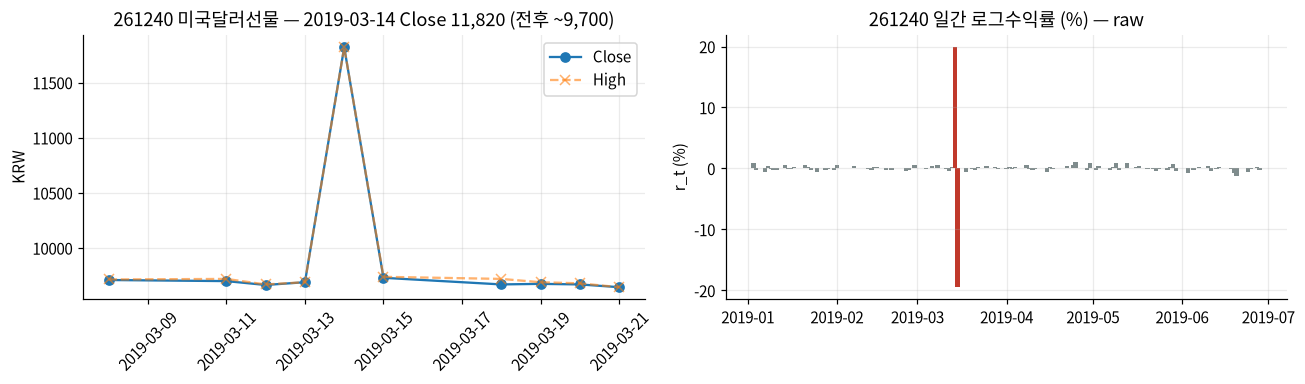

In [12]:
raw_c = D.load_raw_ticker(C, "261240")
win = raw_c[(raw_c.Date >= "2019-03-08") & (raw_c.Date <= "2019-03-21")]
r_raw = D.returns(C, "raw")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(win.Date, win.Close, "o-", label="Close"); axs[0].plot(win.Date, win.High, "x--", alpha=.6, label="High")
axs[0].set_title("261240 미국달러선물 — 2019-03-14 Close 11,820 (전후 ~9,700)"); axs[0].legend(); axs[0].set_ylabel("KRW")
axs[0].tick_params(axis="x", rotation=45)
s = r_raw["261240"].loc["2019-01-03":"2019-06-28"] * 100
axs[1].bar(s.index, s, width=1.5, color=np.where(s.abs() > 10, "#c0392b", "#7f8c8d"))
axs[1].set_title("261240 일간 로그수익률 (%) — raw"); axs[1].set_ylabel("r_t (%)")
fig.tight_layout(); plt.show()

### 상관이라는 결론이 이 flag 들에 얼마나 민감한가
069500 과의 **전체표본** Pearson ρ 를 세 변형으로 계산한다 (rolling 이 아님 — A2 에서 창별로 다시 본다).

In [13]:
sens = Q.dq_corr_sensitivity(C, BASE).set_index("ticker")
display(sens.round(4))
assert abs(sens.loc["261240", "rho_raw"] - (-0.3084)) < 1e-3 and abs(sens.loc["261240", "rho_dq_trim_canonical"] - (-0.4577)) < 1e-3
assert sens.drop(["261240", "153130"])["max_abs_delta"].max() < 0.005

,rho_raw,rho_dq_trim_canonical,rho_mask_all_path_flags,n_masked_path_flags,max_abs_delta
ticker,,,,,
102110,0.9990,0.9990,0.9990,0,0.0000
148070,0.1341,0.1341,0.1341,0,0.0000
153130,0.0462,0.0462,0.0751,2,0.0289
229200,0.6859,0.6859,0.6859,0,0.0000
219480,0.5441,0.5441,0.5473,2,0.0032
133690,0.4477,0.4477,0.4477,0,0.0000
132030,0.2681,0.2681,0.2681,0,0.0000
261220,0.0600,0.0600,0.0600,0,0.0000
261240,-0.3084,-0.4577,-0.4577,2,0.1493


### 해석
- **본 것**: 경로에 닿는 8건 중 기본 패널에 걸리는 것은 261240 2건 · 219480 2건 · 153130 2건 (192090 2건은 패널 밖).
  261240 의 2019-03-14 는 Close 11,820 (전후 약 9,700) → r = +0.199, 다음 날 −0.195. 이 **이틀만** NaN 으로 두면
  ρ(069500, 261240) 가 **−0.308 → −0.458** 로 0.15 움직인다. 연환산 변동성도 13.5% → 8.9%.
  153130 은 spike 후보 2건을 가리면 ρ 0.046 → 0.075 (+0.029), 219480 은 0.544 → 0.547 로 거의 그대로.
- **의미**: 원자료 2일이 전체 7.7년 상관의 크기를 바꾼다 — 단일 관측치가 **분모(분산)** 를 지배하기 때문이다. rolling 창(30/60/120일)에서는
  2019-03 을 포함하는 창 전체가 영향을 받는다. A2 는 261240 을 반드시 `dq_trim_canonical` 로 보고, raw 결과를 병기한다.
- **의미하지 않는 것**: 2019-03-14 가 '오류'라고 확정한 것이 아니다(`price_anomaly_unverified`). 데이터로는 체결 이상인지 실제 가격인지 구분할 수 없다.

### DQ 는 아니지만 영향이 큰 관측치 — |단순수익률| > 15%
flag 가 없다고 해서 창 하나를 지배하지 못하는 것은 아니다. 기본 패널에서 하루 15% 넘게 움직인 날을 따로 적어 둔다 (삭제 대상 아님, A2 민감도 목록).

In [14]:
lm = Q.large_moves(C, BASE)
display(lm.set_index(["ticker", "date"]).round(4))
assert set(lm.loc[lm.has_dq_flag, "ticker"]) == {"261240"}
assert (lm.ticker == "261220").sum() == 8 and set(lm.loc[lm.ticker.isin(["069500", "102110"]), "date"].astype(str)) == {"2026-07-31"}

simple_ret  logret  has_dq_flag
ticker date                                       
069500 2026-07-31      0.2417  0.2165        False
102110 2026-07-31      0.2468  0.2206        False
261220 2020-03-09     -0.2997 -0.3563        False
       2020-03-20      0.1604  0.1487        False
       2020-03-23     -0.1593 -0.1736        False
       2020-04-22     -0.2997 -0.3563        False
       2020-05-06      0.2029  0.1848        False
       2022-03-07      0.1595  0.1479        False
       2026-03-09      0.2931  0.2571        False
       2026-04-08     -0.1768 -0.1946        False
261240 2019-03-14      0.2198  0.1987         True
       2019-03-15     -0.1768 -0.1946         True

### 해석 (DQ 와 대형 변동)
- **대형 변동**: DQ flag 가 없는 15% 초과 변동은 261220(WTI) 8건(2020-03~05 · 2022-03 · 2026-03·04)과 069500·102110 의 2026-07-31(+24%, 기존 anchor A4 창)뿐이다.
  이들은 *실제 극단값일 가능성이 높은* 관측치라 그대로 두지만, 30일 rolling ρ 에서는 하루가 창 분산의 대부분을 차지할 수 있다 →
  A2 에서 "해당일 포함/제외" 민감도를 병기한다.

> **SRM 재구성 질문**
> 1. 220건 중 212건이 상관 분석에 영향을 주지 않는다고 말할 수 있는 근거는?
> 2. 이틀짜리 이상치가 7.7년 전체 상관을 0.15 바꾸는 메커니즘은? rolling 30일 창에서는 영향이 커지는가 작아지는가?

## 7. 기존 canonical 결과 재현 — A 로더가 기존 EDA 와 같은 숫자를 내는가

A 로더(`dq_trim_canonical`)로 기존 closure 표(`reports/tables/universe_vol_rank.csv`, `universe_corr_pearson.csv`, `universe_corr_spearman.csv`)를
다시 계산한다. 기존 표는 `%.6g` 로 저장됐으므로 허용 오차는 **상대 1e-5**. `unrounded` 행은 §3-2 함정을 보여주는 대조행이라 불일치가 *예상*된다.

In [15]:
ep = Q.existing_parity(C, BASE)
display(ep.groupby("check").agg(n=("ticker", "size"), all_match=("match_6g", "all"), max_rel_diff=("rel_diff", "max"),
                                expected_to_match=("expected_to_match", "first")))
assert ep.loc[ep.expected_to_match, "match_6g"].all()

,n,all_match,max_rel_diff,expected_to_match
check,,,,
ann_vol_trimdq,10,True,2.647282e-06,True
pearson_vs_ref_trimdq,9,True,8.186966e-07,True
"spearman_vs_ref_trimdq[logdiff,rank_safe]",9,True,2.318158e-06,True
"spearman_vs_ref_trimdq[logdiff,unrounded]",9,False,3.203605e-05,False
spearman_vs_ref_trimdq[logratio],9,True,2.318158e-06,True


### 해석
- **본 것**: 연환산 변동성 10종, Pearson ρ 9쌍, Spearman ρ 9쌍(logratio 또는 rank_safe) 모두 상대오차 3e-6 이하로 기존 표와 일치.
- **의미**: A2 결과가 기존 60/120/250 분석과 다르면, 원인은 *데이터·수익률 정의*가 아니라 **창·추정량·min_periods** 의 차이다.
  기존 rolling 설정은 서로 다르다(아래 레지스트리) — 비교는 같은 종류끼리만 한다.

> **SRM 재구성 질문**
> 1. 재현 검사의 허용 오차를 1e-5 로 둔 근거는?
> 2. 기존 표와 일치한다는 것이 기존 결론이 '옳다'는 뜻인가?

## 8. A2·A3 로 넘기는 정의 레지스트리 (판단 유보)

**robust-z**: 기존 코드에 3개 변형이 있다. 사용자·교수 승인 전에는 하나를 정답으로 선언하지 않는다(`status: unresolved`).

**기존 rolling 상관**: "60·120·250일" 은 d0122 의 **평균 pairwise** 상관(국내주식 9종 / dedup 17종)이고, KOSPI200 대 개별자산 pair 상관이 아니다.
pair 상관은 120일(final_figs, min_periods=120)과 60/120일(universe_final, min_periods=0.8w)뿐이다. **30일 · 0선 교차 · persistence 는 기존에 없다** → A2 신규.

In [16]:
reg = pd.DataFrame(C.spec["robust_z_registry"]["definitions"]).T[["source", "formula"]]
display(reg)
print("robust-z status:", C.spec["robust_z_registry"]["status"])
display(pd.DataFrame(C.spec["existing_rolling_registry"]).set_index("id")[["windows", "kind", "min_periods"]])
print("A2 제안 (미확정):", C.spec["proposed_for_A2"])
assert C.spec["robust_z_registry"]["status"] == "unresolved"

,source,formula
rz_D,analysis/scripts/universe_final.py rz_D · anal...,"med = r.rolling(60, mp=20).median().shift(1); ..."
rz_A,analysis/scripts/universe_final.py rz_A · src/...,"med = r.rolling(60, mp=40).median().shift(1); ..."
rz_eda_utils,src/eda_utils.extreme_definitions robust_z_shi...,"base=r.shift(1); med=base.rolling(60, mp=30).m..."


robust-z status: unresolved


,windows,kind,min_periods
id,,,
d0122_avg_pairwise,"[60, 120, 250]","평균 pairwise 상관 (domeq9 / dedup17), pearson · s...",w (완전 창)
final_figs_roll_corr,[120],ETF vs 069500 Pearson pair 상관 (+β),120
universe_final_peer,"[60, 120]","pair Pearson, min_periods = 0.8w (fig14/15 은 1...",NaN
universe_final_beta60,[60],"rolling OLS β vs 069500, min_periods 50",NaN
relation_rolling_corr_120,[120],평균 상관 eq14 / all20 / eq12_ex_lev_inv,NaN


A2 제안 (미확정): {'windows': [30, 60, 120], 'methods': ['pearson', 'spearman'], 'min_periods': 'window (완전 창) 기본, 민감도로 0.8·window', 'timing': 'rho_t 는 t 종가까지의 정보로 관측 가능. persistence 를 쓰면 candidate_at / confirmed_at 분리'}


### 해석
- **본 것**: robust-z 는 rz_D(mp20, 잔차 rolling median MAD) · rz_A(mp40, 창 내부 MAD = final_figs) · rz_eda_utils(mp30) 3개. 기존 rolling 은 5종이며 창·min_periods·대상(평균 pairwise vs pair)이 서로 다르다.
- **의미**: A2 의 "기존 60/120/250 과의 정합성"은 **d0122 평균 pairwise 를 같은 방식으로 재현**하거나, pair 120일(final_figs, mp=120)과 비교하는 두 경로뿐이다.
  KOSPI–국고채 pair 의 250일 ρ 는 기존에 없으므로 "기존과 일치"를 주장할 대상이 아니다.

> **SRM 재구성 질문**
> 1. 기존 "60/120/250일 상관"과 A2 의 "KOSPI200–148070 60일 상관"을 직접 비교하면 왜 틀린 결론이 나오는가?
> 2. robust-z 정의를 지금 하나로 확정하지 않는 이유는? (힌트: min_periods 와 MAD 정의가 고변동 국면의 사건 수를 바꾼다)

## 9. 산출물 저장 — run_id 와 입력 버전을 붙여서

`a1_pipeline.run_a1()` 이 이 노트북에서 본 표 전부를 같은 함수로 다시 계산해 저장한다.
파생 패널은 gitignored 디렉터리(`data/processed/research_a/<run_id>/`)에, 그 파일들의 sha256 은 git 추적되는 `A1_RUN_MANIFEST.json` 에 남는다.

In [17]:
from src.r2h.research_a.a1_pipeline import run_a1

res = run_a1(ROOT, run_id=RUN_ID)
display(pd.Series(res["checks"], name=res["run_id"]).to_frame())
print("derived:", res["manifest"]["derived_dir"])
for k, v in res["manifest"]["derived_files"].items():
    print(f"  {k}  rows={v['rows']}  sha256={v['sha256'][:16]}")
assert all(v for k, v in res["checks"].items() if k != "dq_flag_rows")

,A1-20261011T152754-fd9713f7
raw_sha_all_match,True
raw_integrity_all_ok,True
base_panel_calendar_identical,True
interim_close_exact,True
interim_logret_match_1e-15,True
existing_tables_reproduced,True
existing_raw_validation_reproduced,True
dq_flag_rows,220


derived: data/processed/research_a/A1-20261011T152754-fd9713f7
  data/processed/research_a/A1-20261011T152754-fd9713f7/close_panel.csv  rows=1903  sha256=6e30a98c21dd3d7c
  data/processed/research_a/A1-20261011T152754-fd9713f7/logret_raw.csv  rows=1902  sha256=e12cac5f9ece7c4f
  data/processed/research_a/A1-20261011T152754-fd9713f7/logret_dq_trim_canonical.csv  rows=1902  sha256=075798566b368d16
  data/processed/research_a/A1-20261011T152754-fd9713f7/dq_flags_long.csv  rows=220  sha256=41342b0e83072ce7


## 10. 요약 — A1 데이터 계약

| # | 확인 | 결과 | 근거 |
|---|---|---|---|
| 1 | raw 무결성 | sha256 20/20 일치, 각 1,903 행, 결측·중복 0 | §1 |
| 2 | 수익률 정의 | $r_t=\ln(C_t/C_{t-1})$, canonical `panel_logret.csv` 와 ≤1e-16 일치 (index·열·NaN 별도 확인) | §3-1 |
| 3 | 수치 구현 | logdiff(기본) vs logratio ≤1.8e-15 → 순위 통계는 `rank_safe` 후 계산 | §3-2 |
| 4 | 기본 패널 정렬 | 10종 날짜 집합 동일, 공통 1,902 관측. 153130 0수익률 16.8% | §4 |
| 5 | 가격 조정 | ESTIMATED (확정 안 함). Change 는 독립 증거 아님 | §5 |
| 6 | DQ 220건 | 212 = 경로 무관(OHLC), 8 = 경로 관련. 261240 2일이 ρ 를 0.15 이동. 비-DQ 15% 초과 변동 10건(261220 8 · KOSPI200 2) | §6 |
| 7 | 기존 결과 재현 | vol·Pearson·Spearman 기존 표와 상대 3e-6 이내 · raw_validation.csv 5항목+점프날짜 20종 일치 | §5 · §7 |
| 8 | 비교군 | 069500 기준, 102110 대조(독립 집계 금지), exposure dedup | §2 |

**A2 로 넘기는 질문**
1. 153130 처럼 ρ≈0 인 쌍에서 0선 교차를 '구조 변화'와 '잡음'으로 가르는 기준(지속 기간·크기·창 간 동시성)은 무엇인가?
2. overnight_lag 자산(219480·133690·132030·261220)의 동일일 ρ 는 lag 정렬 후에도 유지되는가?
3. 261240 의 2019-03 이상치는 30일 창에서 얼마나 오래 ρ 를 왜곡하는가 (raw vs dq_trim 병기)?

**한계**: 유니버스는 PROVISIONAL. 2019~2026 은 탐색 표본이며 단일 검증 기간이 아니다. 조정주가 여부 미확정.